## Import packages 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import tifffile as tiff
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

from torch.amp import GradScaler
from torch.amp import autocast

import segmentation_models_pytorch as smp

from torchvision.transforms import Compose, ToTensor
import albumentations as A

from PotsdamDataset import PotsdamDataset
from plot_functions import display_image_tensor, display_prediction, plot_train_val_losses, plot_train_val_metrics


## Use below in order to train "Normally" or using autocast and GradScaler to handle mixed precision training

In [ ]:
#   Use this to train (normally) without automatic mixed precision (AMP)
#from training_loop import DiceFocalLoss, output_to_label, training_loop, train_epoch, validate, confusion_matrix_6x6, test_score



#   Use this to train with automatic mixed precision (AMP) for faster training and reduced memory usage
#   using autocast and GradScaler to handle mixed precision training
from training_loop_autocast import DiceFocalLoss, output_to_label, training_loop, train_epoch, validate, confusion_matrix_6x6, test_score

In [2]:
print("segmentation_models_pytorch version:", smp.__version__)

# FocalLoss in version 0.5.0 strictly expects raw logits

segmentation_models_pytorch version: 0.5.0


In [3]:
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA Version:", torch.version.cuda)

PyTorch Version: 2.3.1+cu118
CUDA Available: True
CUDA Version: 11.8


### How many training opatches, and how many validation patches

In [4]:
TRAIN_DIR = Path("train_patches/images")
VAL_DIR = Path("val_patches/images")

image_files = sorted(TRAIN_DIR.glob("*.tif"))
val_files = sorted(VAL_DIR.glob("*.tif"))

print("Train images:", len(image_files))
print("Validation images:", len(val_files))


Train images: 1883
Validation images: 605


# Implementation of CBAM module

In [5]:
"""
AdaptiveAvgPool2d

class torch.nn.AdaptiveAvgPool2d(output_size)

    Applies a 2D adaptive average pooling over an input signal composed of several input planes.

    The output is of size H_out x W_out, for any input size. The number of output features is equal to the number of input planes.

    Input: (N, C, H_in, W_in)
    Output: (N, C, H_out, W_out)  where (H_out, W_out)=output_size
"""

"""
AdaptiveMaxPool2d

class torch.nn.AdaptiveMaxPool2d(output_size, return_indices=False)

    Applies a 2D adaptive max pooling over an input signal composed of several input planes.

    The output is of size H_out x W_out, for any input size. The number of output features is equal to the number of input planes.

    Input: (N, C, H_in, W_in)
    Output: (N, C, H_out, W_out)  where (H_out, W_out)=output_size
"""

'\nAdaptiveMaxPool2d\n\nclass torch.nn.AdaptiveMaxPool2d(output_size, return_indices=False)\n\n    Applies a 2D adaptive max pooling over an input signal composed of several input planes.\n\n    The output is of size H_out x W_out, for any input size. The number of output features is equal to the number of input planes.\n\n    Input: (N, C, H_in, W_in)\n    Output: (N, C, H_out, W_out)  where (H_out, W_out)=output_size\n'

In [6]:
class ChannelAttention(nn.Module):
    # Input: (N, C, H, W) where C is the number of channels
    # Output: (N, C, H, W) where C is the number of channels

    def __init__(self, channels, reduction=16):
        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.mlp = nn.Sequential(
            nn.Conv2d(in_channels = channels, out_channels = channels // reduction, kernel_size = 1, stride=1, padding=0, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels = channels // reduction, out_channels = channels, kernel_size = 1, stride=1, padding=0, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = self.mlp(self.avg_pool(x))
        max_out = self.mlp(self.max_pool(x))

        channel_attention = self.sigmoid(avg_out + max_out)

        # element-wise multiplication of the input feature map and the channel attention map
        return x * channel_attention

In [7]:
class SpatialAttention(nn.Module):
    # Input: (N, C, H, W) where C is the number of channels
    # Output: (N, C, H, W) where C is the number of channels

    def __init__(self, kernel_size=7):
        super().__init__()

        padding = kernel_size // 2

        # in_channels=2 because we will concatenate the average and max pooled features along the channel dimension
        # i.e. avg_pooling and max_pooling will each produce a single channel, so when we concatenate them, we get 2 channels.
        self.conv = nn.Conv2d(in_channels=2, out_channels=1, kernel_size=kernel_size, padding=padding, bias=False)

        self.sigmoid = nn.Sigmoid()


    def forward(self, x):

        # dim=1 corresponds to the channel dimension in a tensor of shape (N, C, H, W), 
        # where N is the batch size, C is the number of channels, H is the height, and W is the width.
        avg_out = torch.mean(x, dim=1, keepdim=True )

        # max along the channel dimension (dim=1) of the input tensor x, 
        # while keeping the dimensions of the output tensor the same as the input tensor.
        max_out, _ = torch.max(x, dim=1, keepdim=True )

        # concatenate the average and max pooled features along the channel dimension
        attention = torch.cat( [avg_out, max_out], dim=1 )

        # apply the convolution and sigmoid activation to the concatenated features
        spatial_attention = self.sigmoid( self.conv(attention) )

        # element-wise multiplication of the input feature map and the spatial attention map
        return x * spatial_attention

In [8]:
class CBAM(nn.Module):
    """
    CBAM (Convolutional Block Attention Module) is a lightweight attention module for convolutional neural networks.
    It sequentially applies channel and spatial attention to the input feature map, enhancing the representational
    power of the network by focusing on informative features while suppressing less useful ones.

    Args:
        channels (int): Number of channels in the input feature map. 
                        Will also be the number of channels in the output feature map, as CBAM does not change the number of channels.
        
        reduction (int): Reduction ratio for the channel attention module. Default is 16.
        
        kernel_size (int): Kernel size for the spatial attention module. Default is 7.
    
    Input:
        x (torch.Tensor):   Input feature map of shape (N, C, H, W)
    
    Output:
        torch.Tensor:       Output feature map of shape (N, C, H, W)
                            

    """
    def __init__(self, channels, reduction=16, kernel_size=7):
        super().__init__()

        self.channel_attention = ChannelAttention(channels, reduction)
        self.spatial_attention = SpatialAttention(kernel_size)


    def forward(self, x):
        x = self.channel_attention(x)
        x = self.spatial_attention(x)

        return x

# Build U-Net with CBAM model for semantic segmentation 

PyTorch expects images in (channels × height × width) format, or (C, H, W).
- Single Image: (C, H, W) — for example, a 3-channel RGB image is ``(3, H, W)``.
- Batch of Images: ``(B, C, H, W)`` — where B is the batch size

- Unlike libraries like Matplotlib, OpenCV, or NumPy/PIL arrays which typically use (H, W, C) (channels-last), PyTorch standardizes on "channels-first" (C, H, W) for its convolutional layers and transforms.

## Model architecture

- Design follows the original U-Net architecture with the exception that the downsampling are done in three stages instead of four, and the upsampling is done in three stages as well.
    - This choice was made in order to have less parameters to train

- Padding of 1 is applied to all 3x3 conv layers in order to keep image dimensions intact

- Skip-connections
    - Endoced data is run thorugh CBAM modules, and thereafter concatenated to up-sampled data (with the same dimensions)  


In [9]:
class UNet_CBAM(nn.Module):

    def __init__(self, img_dim:int, n_class:int, in_channels:int=3):

        super().__init__()
        
        self.n_class = n_class
        self.in_channels = in_channels
        self.out_channels = n_class
        self.img_dim = img_dim

        if self.img_dim  < 256:
            raise ValueError("Image dimension must be at least 256x256 for this U-Net implementation.")
        if self.img_dim % 256 != 0:
            raise ValueError("Image dimension must be a multiple of 256 for this U-Net implementation.")


        # Define the U-Net model using torch.nn


        # ---- MAXPOOLING ----
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)



        # ---- ENCODER ----
        
        # output sent to CBAM in skip connection
        self.encode_1 = nn.Sequential(
            nn.Conv2d(self.in_channels, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))
        
        # output sent to CBAM in skip connection
        self.encode_2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))
        
        # output sent to CBAM in skip connection
        self.encode_3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))



        # ---- BRIDGE ---- 
        # to connect encoder and decoder
        self.bridge = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))



        # ---- CBAM Attention Modules ----
        self.cbam_1 = CBAM(channels=64, reduction=16, kernel_size=7)
        self.cbam_2 = CBAM(channels=128, reduction=16, kernel_size=7)
        self.cbam_3 = CBAM(channels=256, reduction=16, kernel_size=7)



        # ---- UP-SAMPLING ----
        # Up-convolution layers to up-sample the feature maps back to the original image size

        # increase the spatial dimensions (64 --> 128), decrease the number of channels (512 --> 256)
        self.upconv_3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)

        # increase the spatial dimensions (128 --> 256), decrease the number of channels (256 --> 128)
        self.upconv_2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        
        # increase the spatial dimensions (256 --> 512), decrease the number of channels (128 --> 64)
        self.upconv_1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)



        # ---- DECODER -----
        self.decode_3 = nn.Sequential(
            nn.Conv2d(512, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))

        self.decode_2 = nn.Sequential(
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))

        self.decode_1 = nn.Sequential(
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))


        # ---- FINAL CONVOLUTION LAYER ----
        # Final layer to map to the desired number of classes
        self.final_conv = nn.Conv2d(64, self.out_channels, kernel_size=1)  




    def forward(self, x):

        # --- Encoder ---
        encoded_1 = self.encode_1(x)

        x = self.maxpool(encoded_1)

        encoded_2 = self.encode_2(x)

        x = self.maxpool(encoded_2)

        encoded_3 = self.encode_3(x)

        x = self.maxpool(encoded_3)



        # --- Bridge ---
        x = self.bridge(x)



        # --- Decoder ---
        
        # increase the spatial dimensions (64 --> 128)
        # decrease the number of channels (512 --> 256)
        x = self.upconv_3(x) 

        # Apply CBAM attention to the skip connection feature map from the encoder
        cbam_3_out = self.cbam_3(encoded_3)

        # Concatenate along the channel dimension, dim=1  
        # since PyTorch uses (N,C,H,W) format, where N is batch size, C is channels, H is height, W is width
        # number of channels after concatenation will be 256 (from upconv_3) + 256 (from cbam_3_out) = 512
        x = torch.cat((cbam_3_out, x), dim=1)

        x = self.decode_3(x)



        # increase the spatial dimensions (128 --> 256)
        # decrease the number of channels (256 --> 128)
        x = self.upconv_2(x)

        # Apply CBAM attention to the skip connection feature map from the encoder
        cbam_2_out = self.cbam_2(encoded_2)

        # number of channels after concatenation will be 128 (from upconv_2) + 128 (from cbam_2_out) = 256
        x = torch.cat((cbam_2_out, x), dim=1)
        
        x = self.decode_2(x)



        # increase the spatial dimensions (256 --> 512)
        # decrease the number of channels (128 --> 64)
        x = self.upconv_1(x)

        # Apply CBAM attention to the skip connection feature map from the encoder
        cbam_1_out = self.cbam_1(encoded_1)

        # number of channels after concatenation will be 64 (from upconv_1) + 64 (from cbam_1_out) = 128
        x = torch.cat((cbam_1_out, x), dim=1)
        
        x = self.decode_1(x)



        # --- Final layer --- 
        # to map to the desired number of classes
        x = self.final_conv(x)

        return x


# Initialize datasets and dataloaders

In [10]:
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5), ])


train_dataset = PotsdamDataset(root="./train_patches", transform=train_transform)
val_dataset = PotsdamDataset(root="./val_patches", transform=None)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)

In [11]:
print(f"The example dataset is: {train_dataset}")
print(f"The example dataset type is: {type(train_dataset)}\n")
number_of_samples = len(train_dataset)
print(f"The number of samples is: {number_of_samples}\n")

img, label = train_dataset[200]

print(type(img), type(label))
print(img.dtype, label.dtype)
print(img.shape, label.shape)


The example dataset is: <PotsdamDataset.PotsdamDataset object at 0x7e86af99d950>
The example dataset type is: <class 'PotsdamDataset.PotsdamDataset'>

The number of samples is: 1883

<class 'torch.Tensor'> <class 'torch.Tensor'>
torch.float32 torch.int64
torch.Size([3, 512, 512]) torch.Size([512, 512])


Image shape: torch.Size([3, 512, 512])  
Label shape: torch.Size([512, 512])


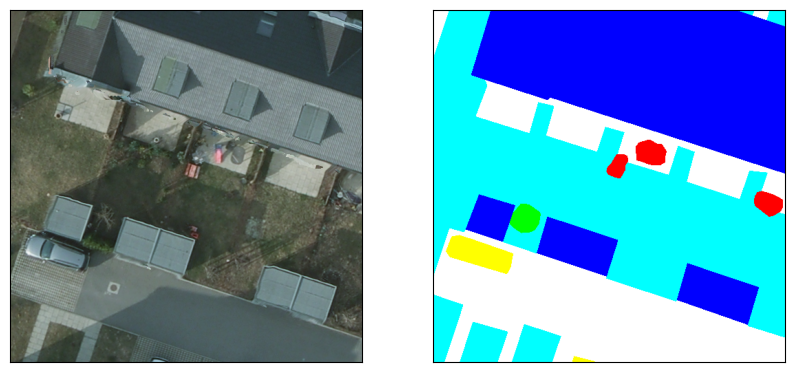

In [12]:
img, label = train_dataset[54]

print(f"Image shape: {img.shape}  \nLabel shape: {label.shape}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
display_image_tensor(axes[0], img)
display_image_tensor(axes[1], label)


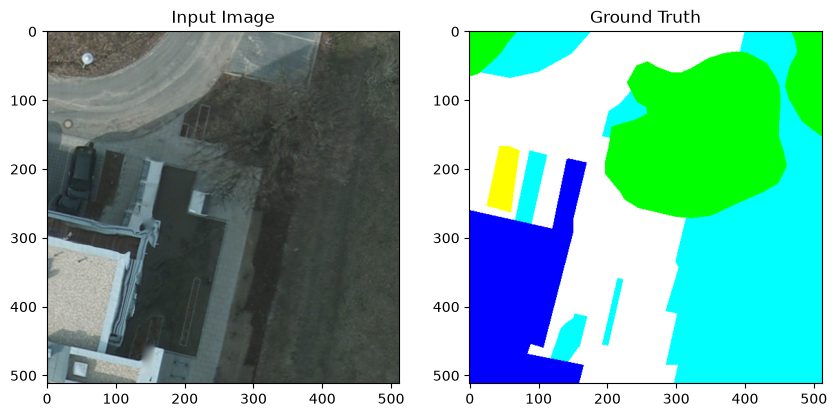

In [13]:
img, label = train_dataset.get_tif_by_id("2_12_512_1024")

plt.subplots(1, 2, figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Input Image')
plt.imshow(img)
plt.subplot(1, 2, 2)
plt.imshow(label)
plt.title('Ground Truth')
plt.show()

# Training starts

In [14]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

In [15]:
print(torch.cuda.memory_allocated() / 1024**3)
print(torch.cuda.memory_reserved() / 1024**3)

0.0
0.0


In [16]:
print(torch.cuda.memory_summary())

|===========================================================================|
|                  PyTorch CUDA memory summary, device ID 0                 |
|---------------------------------------------------------------------------|
|            CUDA OOMs: 0            |        cudaMalloc retries: 0         |
|===========================================================================|
|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |
|---------------------------------------------------------------------------|
| Allocated memory      |      0 B   |      0 B   |      0 B   |      0 B   |
|       from large pool |      0 B   |      0 B   |      0 B   |      0 B   |
|       from small pool |      0 B   |      0 B   |      0 B   |      0 B   |
|---------------------------------------------------------------------------|
| Active memory         |      0 B   |      0 B   |      0 B   |      0 B   |
|       from large pool |      0 B   |      0 B   |      0 B   |

In [17]:
# OBS! 
# model is named "model"

model = UNet_CBAM(img_dim=512, n_class=6, in_channels=3)

optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_fn = DiceFocalLoss(w1=1, w2=1)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.4, patience=5, min_lr=1e-6)

num_epochs = 80


pytorch_total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model.__class__.__name__)
print(f"Total trainable parameters: {pytorch_total_params} \n")


# START MODEL TRAINING
# --------------------
model, train_metrics, val_metrics = training_loop(
        model, optimizer, loss_fn, train_loader, val_loader, num_epochs, scheduler=scheduler, print_every=None)

UNet_CBAM
Total trainable parameters: 7708716 

Starting training


/home/edvard_edsgard/conda/envs/dml/lib/python3.11/site-packages/torch/nn/modules/conv.py:456: UserWarning: Applied workaround for CuDNN issue, install nvrtc.so (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:84.)
  return F.conv2d(input, weight, bias, self.stride,


Epoch 1/80: 
Avg. Train loss: 2.620,  Train mean IoU: 0.134, Learning Rate: 0.00100, 
Avg. Val. loss: 2.095, Val. mean IoU: 0.236

Per-class IoU of Validation Set:
  -> Class 0 IoU: 0.4737
  -> Class 1 IoU: 0.3347
  -> Class 2 IoU: 0.3164
  -> Class 3 IoU: 0.0109
  -> Class 4 IoU: 0.2821
  -> Class 5 IoU: 0.0000

Epoch 2/80: 
Avg. Train loss: 1.772,  Train mean IoU: 0.298, Learning Rate: 0.00100, 
Avg. Val. loss: 1.732, Val. mean IoU: 0.329

Per-class IoU of Validation Set:
  -> Class 0 IoU: 0.5600
  -> Class 1 IoU: 0.5135
  -> Class 2 IoU: 0.4225
  -> Class 3 IoU: 0.0142
  -> Class 4 IoU: 0.3708
  -> Class 5 IoU: 0.0906

Epoch 3/80: 
Avg. Train loss: 1.627,  Train mean IoU: 0.335, Learning Rate: 0.00100, 
Avg. Val. loss: 1.694, Val. mean IoU: 0.327

Per-class IoU of Validation Set:
  -> Class 0 IoU: 0.5571
  -> Class 1 IoU: 0.4901
  -> Class 2 IoU: 0.4415
  -> Class 3 IoU: 0.0006
  -> Class 4 IoU: 0.3708
  -> Class 5 IoU: 0.1042

Epoch 4/80: 
Avg. Train loss: 1.544,  Train mean IoU: 0

# Plots after training and validation metrics 


Length of train_losses: 9440, Length of val_losses: 80


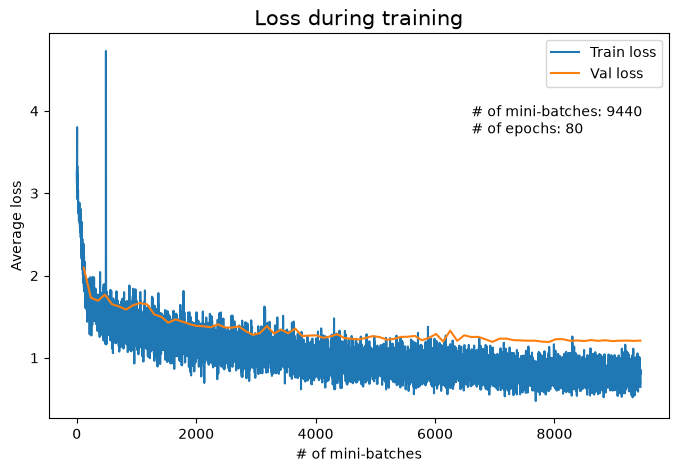

In [20]:
train_losses = train_metrics['loss'] 
val_losses = val_metrics['loss']


plot_train_val_losses(train_losses, val_losses, fig_size=(8,5), file_name="UNet_CBAM_loss_during_training") # "UNet_CBAM_loss_during_training"


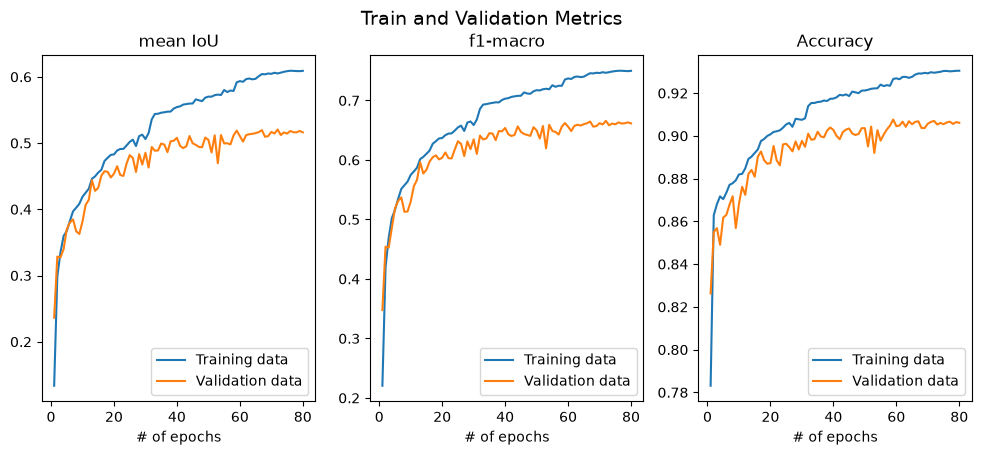

In [21]:
plot_train_val_metrics(train_metrics, val_metrics, fig_size=(12,4.5), file_name="UNet_CBAM_metrics_training") # "UNet_CBAM_metrics_training"

# Displays of predictions
## best model after XX epochs 

In [23]:
best_model = UNet_CBAM(img_dim=512, n_class=6, in_channels=3)

best_model.load_state_dict(torch.load('UNet_CBAM_model_epoch67_run2.pth'))

#print(best_model)

<All keys matched successfully>

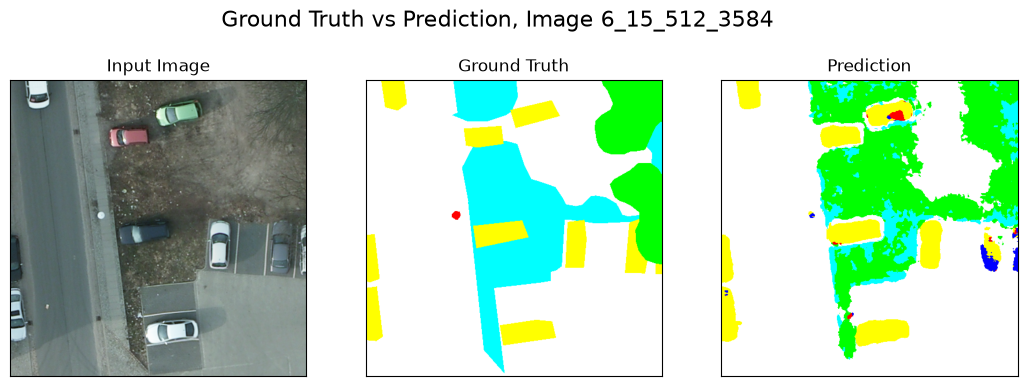

In [24]:
display_prediction(best_model, val_dataset, 600, fig_size=(13, 4.5), file_name=None)


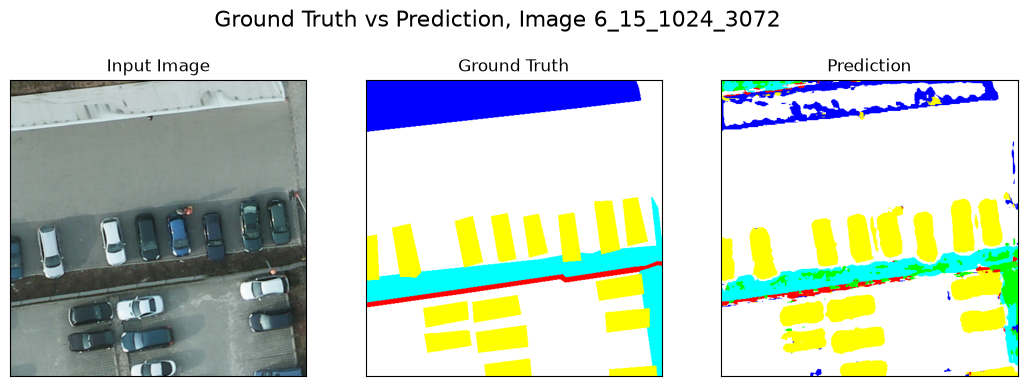

In [38]:
display_prediction(best_model, val_dataset, 500, fig_size=(13, 4.5), file_name="prediction_val500_run2_CBAM")


# Test data performance

In [39]:
test_dataset = PotsdamDataset(root="./test_patches", transform=None)

test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)

In [40]:
# evaluating test data

conf_matrix, test_miou, test_f1_macro, test_accuracy = test_score(best_model, loss_fn, test_loader)

Test mean IoU: 0.496
Test F1 Score (macro): 0.641
Test Accuracy: 0.906

Per-class IoU of Test set:
  -> Class 0 IoU: 0.6442
  -> Class 1 IoU: 0.6487
  -> Class 2 IoU: 0.5505
  -> Class 3 IoU: 0.4149
  -> Class 4 IoU: 0.5783
  -> Class 5 IoU: 0.1384



In [41]:
conf_matrix_ = conf_matrix.numpy()
conf_matrix_

array([[77175517,  7062487,  5590377,  3808404,   387337,  1486219],
       [11634036, 54146195,  1830507,  1541495,   946401,  2226470],
       [ 2685214,   966110, 42654865,  8911511,    45509,   804231],
       [ 4509951,   771667, 11804986, 24049674,   145786,   779440],
       [  416227,   405962,    40162,    46367,  4407950,   367902],
       [ 5038067,  1933056,  2148634,  1595615,   412114,  2698371]])

In [42]:
norm_conf_matrix_ = conf_matrix_.astype('float') / conf_matrix_.sum(axis=1)[:, np.newaxis]
norm_conf_matrix_


array([[0.8080331 , 0.07394474, 0.05853164, 0.03987426, 0.00405545,
        0.01556082],
       [0.16085751, 0.74865008, 0.02530943, 0.02131342, 0.01308537,
        0.03078419],
       [0.04789257, 0.01723121, 0.76077782, 0.15894271, 0.00081168,
        0.01434399],
       [0.10722277, 0.01834616, 0.2806601 , 0.57177399, 0.00346602,
        0.01853096],
       [0.07322049, 0.07141472, 0.00706509, 0.00815664, 0.77542365,
        0.06471941],
       [0.36439455, 0.13981455, 0.15540693, 0.11540804, 0.02980748,
        0.19516844]])

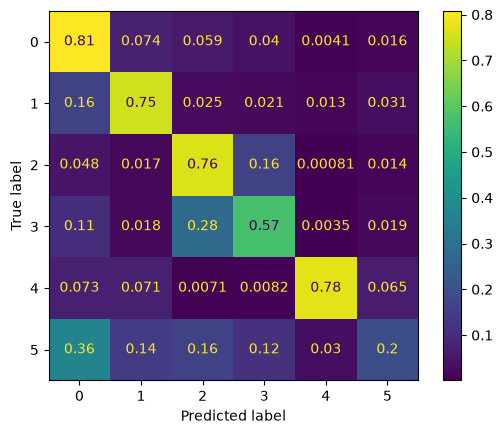

In [43]:
disp = ConfusionMatrixDisplay(confusion_matrix=norm_conf_matrix_,
                              display_labels=[0,1,2,3,4,5],
                             )

disp.plot()
plt.show()

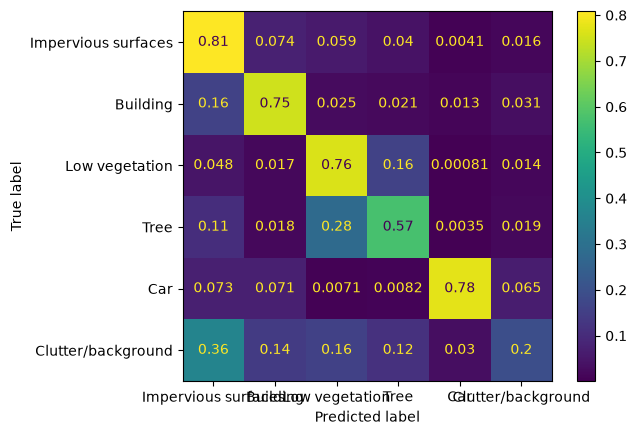

In [44]:
text_labels = ["Impervious surfaces", "Building",  "Low vegetation", "Tree", "Car", "Clutter/background"]

disp = ConfusionMatrixDisplay(confusion_matrix=norm_conf_matrix_,
                              display_labels=text_labels,
                             )

disp.plot()
plt.show()